In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   Дата          301355 non-null  object
 1   Склад         301355 non-null  int64 
 2   Контрагент    301355 non-null  object
 3   Номенклатура  301355 non-null  object
 4   Количество    301355 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.5+ MB


Сразу переведем столбец "Дата" в правильный формат

In [5]:
df["Дата"] = pd.to_datetime(df["Дата"], format="%Y-%m-%d")

print(df.dtypes)

Дата            datetime64[ns]
Склад                    int64
Контрагент              object
Номенклатура            object
Количество               int64
dtype: object


Сгруппируйте данные по дате, посчитайте количество продаж

In [6]:
grouped_df = (
    df.groupby("Дата")
      .size()
      .reset_index(name="Количество_продаж")
)

          Дата  Количество_продаж
0   2018-01-04               1840
1   2018-01-05               1301
2   2018-01-06               1306
3   2018-01-07               1322
4   2018-01-09               1719
..         ...                ...
200 2018-08-26               1462
201 2018-08-28               1731
202 2018-08-29               1497
203 2018-08-30               1445
204 2018-08-31               1366

[205 rows x 2 columns]


Вывести несколько первых строк сгруппированных данных

In [9]:
grouped_df.head()

,Дата,Количество_продаж
0,2018-01-04,1840
1,2018-01-05,1301
2,2018-01-06,1306
3,2018-01-07,1322
4,2018-01-09,1719


Нарисуйте график продаж у `grouped_df`

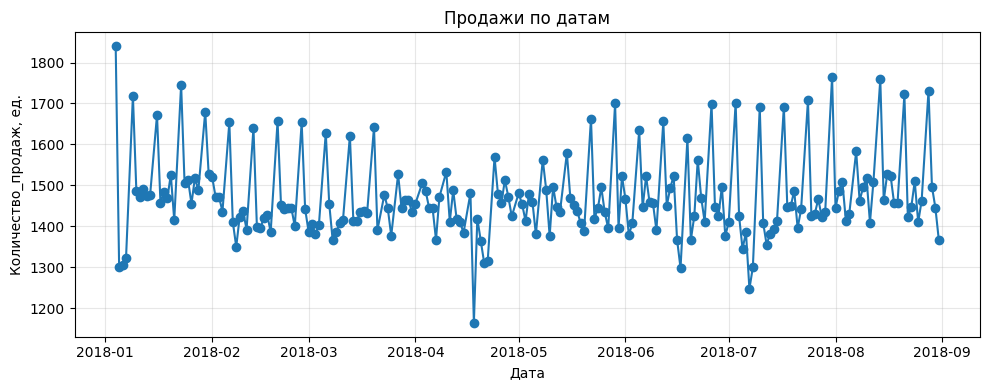

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(grouped_df["Дата"], grouped_df["Количество_продаж"], marker="o")
plt.title("Продажи по датам")
plt.xlabel("Дата")
plt.ylabel("Количество_продаж, ед.")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

- Продажи постоянно скачут, резкие взлёты сменяются стремительными падениями
- В среднем они держутся в пределах 1300-1700 ед.
- Самые высокие продажи были зафиксированы в январе, самые низкие - во второй половине апреля
- С января по март продажи шли +- ровно, после чего они сильно просели в апреле-мае, и снова вернулись к зимним значениям в июне
- Учитывая, что рост продаж отражается в единичных точках, а снижение - скоплением, вероятно, пики продаж наблюдались в выходные или праздничные дни, а спад - в будни

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [13]:
from scipy.stats import zscore

In [17]:
grouped_df['z_score'] = zscore(grouped_df['Количество_продаж'])

max_outlier = grouped_df.loc[grouped_df['z_score'].idxmax()]

print("День с максимальным выбросом:")
print(max_outlier)

День с максимальным выбросом:
Дата                 2018-01-04 00:00:00
Количество_продаж                   1840
z_score                         3.625924
Name: 0, dtype: object


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [18]:
filtered_df = df[
    (df['Склад'] == 3) &
    (df['Дата'].dt.month.isin([6, 7, 8])) &
    (df['Дата'].dt.dayofweek == 2)
]

top_products = (
    filtered_df.groupby('Номенклатура')['Количество']
    .sum()
    .reset_index()
    .sort_values(by='Количество', ascending=False)
)

top_products.head(1)

,Номенклатура,Количество
1,product_1,2267


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [39]:
weather = pd.read_csv(
    'astana_weather.csv.gz',
    sep=';',
    skiprows=6,
    encoding='utf-8'
)

weather = weather.reset_index()

weather.head()

,index,Местное время в Астане,T,Po,P,Pa,U,DD,Ff,ff10,...,Cm,Ch,VV,Td,RRR,tR,E,Tg,E',sss
0,01.09.2018 23:00,5.5,737.1,769.1,0.1,84.0,"Ветер, дующий с северо-северо-востока",2,NaN,NaN,...,NaN,NaN,2.9,Следы осадков,12.0,NaN,NaN,NaN,NaN,NaN
1,01.09.2018 20:00,6.1,737.0,769.0,1.0,78.0,"Ветер, дующий с севера",2,NaN,NaN,...,"Перистых, перисто-кучевых или перисто-слоистых...",NaN,2.5,Следы осадков,12.0,NaN,NaN,NaN,NaN,NaN
2,01.09.2018 17:00,7.5,736.0,767.7,0.2,78.0,"Ветер, дующий с северо-востока",1,NaN,NaN,...,"Перистых, перисто-кучевых или перисто-слоистых...",10.0,3.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01.09.2018 14:00,9.1,735.8,767.4,-0.5,55.0,"Ветер, дующий с северо-северо-востока",3,NaN,NaN,...,"Перистых, перисто-кучевых или перисто-слоистых...",10.0,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01.09.2018 11:00,7.7,736.3,768.1,-0.2,61.0,"Ветер, дующий с северо-северо-востока",3,NaN,NaN,...,NaN,10.0,0.5,Следы осадков,12.0,NaN,NaN,NaN,NaN,NaN


In [38]:
daily_temp = weather.iloc[:, [0, 1]].copy()
daily_temp.columns = ['Дата', 'T']

daily_temp['Дата'] = pd.to_datetime(daily_temp['Дата'], dayfirst=True, errors='coerce')

daily_temp['Дата'] = daily_temp['Дата'].dt.normalize()
daily_temp = daily_temp.groupby('Дата', as_index=False)['T'].mean()

daily_temp.head()

,Дата,T
0,2018-01-01,-9.4625
1,2018-01-02,-9.5125
2,2018-01-03,-11.4625
3,2018-01-04,-14.0750
4,2018-01-05,-16.8625


In [46]:
merged_df = pd.merge(grouped_df, daily_temp, on='Дата', how='inner')
merged_df = merged_df.drop(columns=['z_score'], errors='ignore')

merged_df.head()

,Дата,Количество_продаж,T
0,2018-01-04,1840,-14.0750
1,2018-01-05,1301,-16.8625
2,2018-01-06,1306,-13.3000
3,2018-01-07,1322,-12.7500
4,2018-01-09,1719,-6.2500


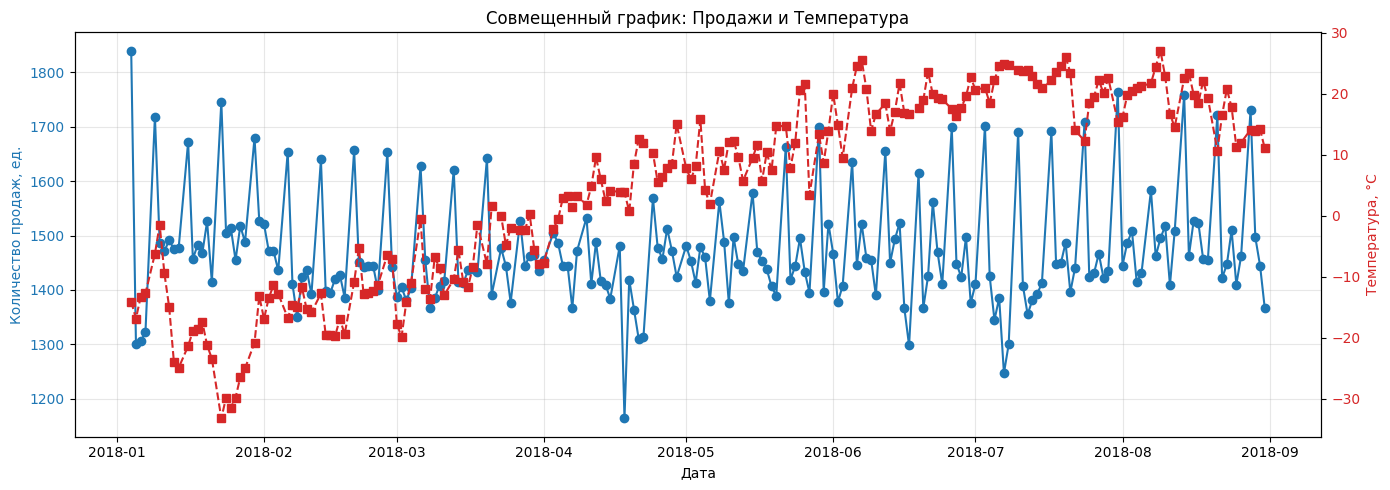

In [51]:
fig, ax1 = plt.subplots(figsize=(14, 5))

color = 'tab:blue'
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж, ед.', color=color)
ax1.plot(merged_df['Дата'], merged_df['Количество_продаж'], color=color, marker='o', label='Продажи')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Температура, °C', color=color)
ax2.plot(merged_df['Дата'], merged_df['T'], color=color, marker='s', linestyle='--', label='Температура')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Совмещенный график: Продажи и Температура')
fig.tight_layout()
plt.show()